# Customer Churn Prediction — Preprocessing, ML & Streamlit Integration





## 1. Imports and reproducibility

import the libraries used for data preparation, model training, evaluation, and saving the final artifact.

In [90]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pandas.api.types import is_object_dtype, is_string_dtype

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42
DATA_PATH = "Telco-Customer-Churn.csv"
ARTIFACT_PATH = "churn_model.pkl"
METADATA_PATH = "churn_model_metadata.json"

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")



## 2. Load and validate the raw dataset

In [91]:
data_file = Path(DATA_PATH)
if not data_file.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH!r}. Place the CSV beside this notebook or update DATA_PATH.")

df_raw = pd.read_csv(data_file)
print("Raw shape:", df_raw.shape)


print("Duplicate rows:", int(df_raw.duplicated().sum()))
print("Duplicate customer IDs:", int(df_raw["customerID"].duplicated().sum()))
print("Target values:", sorted(df_raw["Churn"].dropna().astype(str).unique()))
print("\nDataFrame Info:\n")

df_raw.info()

df_raw.head()


Raw shape: (7043, 21)
Duplicate rows: 0
Duplicate customer IDs: 0
Target values: ['No', 'Yes']

DataFrame Info:

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.950,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.300,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.65,Yes


## 3. Data preprocessing and quality checks

TotalCharges column is stored as text , so it must be converted to numeric and turn blank into missing values.
the imputation step is fitted later inside the pipeline using training data only to avoid data leakag.

In [92]:
df = df_raw.copy()

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce")

if df["Churn"].isna().any():
    raise ValueError("the target column churn contains missing values")

df = df[df["Churn"].isin(["Yes", "No"])].copy()

print("Prepared shape:", df.shape)
print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("missing_count"))
print("Missing TotalCharges:", int(df["TotalCharges"].isna().sum()))
print("Zero-tenure customers:", int((df["tenure"] == 0).sum()))
print("\nTarget distribution:")
display(df["Churn"].value_counts().rename_axis("Churn").to_frame("customers").assign(percentage=lambda x: (100 * x["customers"] / x["customers"].sum()).round(2)))
print("totalcharge column data type is:", df["TotalCharges"].dtype)


Prepared shape: (7043, 21)
Missing values by column:


,missing_count
TotalCharges,11
customerID,0
DeviceProtection,0
MonthlyCharges,0
PaymentMethod,0
PaperlessBilling,0
Contract,0
StreamingMovies,0
StreamingTV,0
TechSupport,0


Missing TotalCharges: 11
Zero-tenure customers: 11

Target distribution:


,customers,percentage
Churn,,
No,5174,73.460
Yes,1869,26.540


totalcharge column data type is: float64


TotalCharges column need to be invistigated further to decied how to deal with missing values

In [93]:
# export the cleaned dataset for team analysis.
output_path = Path("Telco_Customer_Churn_Preprocessed.csv")

df.to_csv(output_path, index=False)

print(f"Dataset exported successfully: {output_path.resolve()}")
print(f"Dataset shape: {df.shape}")

Dataset exported successfully: E:\depi\final project\Telco_Customer_Churn_Preprocessed.csv
Dataset shape: (7043, 21)


## 4. Define features and split the data

customerID is an identifier, so it should be excludeed from the predictive features. and the test set will be separated until the final evaluation. reserve a small, independent holdout is reserve for feature importance; this means those observations are not used to fit or select the model. The remaining data will be divided into training and validation sets.

In [94]:
X = df.drop(columns=["Churn", "customerID"], errors="ignore").copy()
y = df["Churn"].map({"No": 0, "Yes": 1}).astype(int)

if y.nunique() != 2:
    raise ValueError("Churn target must contain both classes after cleaning.")

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

# split the remaining 80% into 60% training, 10% validation, and 10% feature-importance data.
X_train, X_holdout, y_train, y_holdout = train_test_split(X_train_full, y_train_full, test_size=0.25,stratify=y_train_full, random_state=RANDOM_STATE)

X_valid, X_importance, y_valid, y_importance = train_test_split(X_holdout, y_holdout, test_size=0.50,stratify=y_holdout, random_state=RANDOM_STATE)


print("Model-fit subset:", X_train.shape)
print("Validation set:", X_valid.shape)
print("Feature-importance holdout:", X_importance.shape)
print("Untouched test set:", X_test.shape)


Model-fit subset: (4225, 19)
Validation set: (704, 19)
Feature-importance holdout: (705, 19)
Untouched test set: (1409, 19)


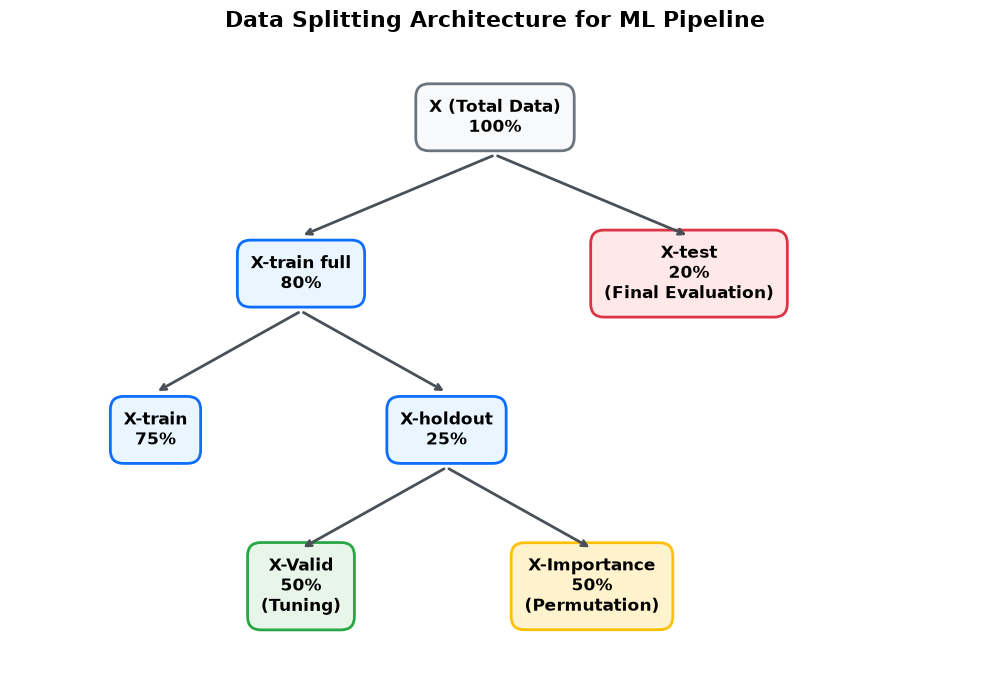

In [95]:

# visulize data splitting hierarchy

import matplotlib.pyplot as plt

# Set figure size and hide axes
fig, ax = plt.subplots(figsize=(10, 7))
ax.axis('off')

# Node and edge styling
def draw_node(text, x, y, bg_color="#e9f5ff", border_color="#0d6efd"):
    ax.text(x, y, text, ha="center", va="center", size=12, fontweight='bold', 
            bbox=dict(boxstyle="round,pad=0.8", fc=bg_color, ec=border_color, lw=2))

def draw_edge(x1, y1, x2, y2):
    # Draw an arrow between two points
    ax.annotate("", xy=(x2, y2+0.06), xytext=(x1, y1-0.06), 
                arrowprops=dict(arrowstyle="->", color="#495057", lw=2))

# 1. Draw nodes (boxes) and position them geometrically based on the architecture
# Level 1: Full Dataset
draw_node("X (Total Data)\n100%", 0.5, 0.9, bg_color="#f8f9fa", border_color="#6c757d")

# Level 2: First Split (Train/Test)
draw_node("X-train full\n80%", 0.3, 0.65)
draw_node("X-test\n20%\n(Final Evaluation)", 0.7, 0.65, bg_color="#ffe8e8", border_color="#dc3545") 

# Level 3: Second Split (Train/Holdout)
draw_node("X-train\n75%", 0.15, 0.4)
draw_node("X-holdout\n25%", 0.45, 0.4)

# Level 4: Third Split (Validation/Importance)
draw_node("X-Valid\n50%\n(Tuning)", 0.3, 0.15, bg_color="#e8f5e9", border_color="#28a745") 
draw_node("X-Importance\n50%\n(Permutation)", 0.6, 0.15, bg_color="#fff3cd", border_color="#ffc107") 

# 2. Draw connections (arrows)
# Connections from Level 1 to 2
draw_edge(0.5, 0.9, 0.3, 0.65)
draw_edge(0.5, 0.9, 0.7, 0.65)

# Connections from Level 2 to 3
draw_edge(0.3, 0.65, 0.15, 0.4)
draw_edge(0.3, 0.65, 0.45, 0.4)

# Connections from Level 3 to 4
draw_edge(0.45, 0.4, 0.3, 0.15)
draw_edge(0.45, 0.4, 0.6, 0.15)

# Add main title and adjust layout
plt.title("Data Splitting Architecture for ML Pipeline", fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()

# Save the figure as a high-resolution image for the final report
plt.savefig("data_splitting_hierarchy.png", dpi=300, bbox_inches='tight')

# Display the plot in the Jupyter Notebook
plt.show()


## 5. Build a preprocessing pipeline

For numeric columns, median imputation followed by standardization is will be used . For categorical columns, most-frequent imputation followed by one-hot encoding will be used. Keeping these steps inside a pipeline ensures that imputation and scaling are fitted on the training data within each cross-validation fold, rather than on the full dataset.

In [96]:
# identify categorical columns across different data types for flexible preprocessing.
def get_categorical_columns(frame):
    return [
        col for col in frame.columns
        if is_object_dtype(frame[col]) or is_string_dtype(frame[col])
        or isinstance(frame[col].dtype, pd.CategoricalDtype)]

# Separate numerical and categorical features.
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = get_categorical_columns(X_train)

# display detected features for validation.
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

# impute missing numerical values and standardize numerical features.
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())])

# impute missing categorical values and one-hot encode categories
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))])

# combine both transformers into a single preprocessor
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)])

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 6. Create a baseline model

we will use DummyClassifier that always predicts the majority class. This gives a simple reference point. Since most customers in this dataset did not churn, the baseline will have a high Accuracy while achieving zero Recall.

In [97]:

# create a baseline model using the most frequent class strategy
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_valid)

# evaluate the baseline model's performance on the validation set
baseline_results = pd.DataFrame([{
    "Model": "Most-frequent baseline",
    "Accuracy": accuracy_score(y_valid, baseline_pred),
    "Precision": precision_score(y_valid, baseline_pred, zero_division=0),
    "Recall": recall_score(y_valid, baseline_pred, zero_division=0),
    "F1": f1_score(y_valid, baseline_pred, zero_division=0)}]).set_index("Model")

display(baseline_results.round(3))

,Accuracy,Precision,Recall,F1
Model,,,,
Most-frequent baseline,0.734,0.000,0.000,0.000


zero Recall means the majority-class model fails to identify any churners. therefore we will be using Recall as the primary metric rather than relying on Accuracy alone.

## 7. Choose the candidate models before training

4 models from different modeling approaches will be used :

- Logistic Regression: an interpretable linear baseline.
- Random Forest: an ensemble of decision trees that can learn nonlinear patterns.
- Extra Trees: a related tree ensemble with more randomized splits, included to test whether this changes generalization.
- XGBoost: a gradient-boosting model that builds trees sequentially to correct earlier errors. This is the new candidate because it represents a different ensemble strategy from Random Forest and Extra Trees.

Recall is the primary selection metric because the project focuses on identifying customers who actually churn. but, F1, Precision, PR-AUC, and ROC-AUC will be take into account so a higher Recall is not interpreted without considering false alarms and overall discrimination.


In [98]:
%%time

# combine preprocessing and model into a single pipeline.
def make_pipeline(estimator):
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator),
    ])

# initialize the candidate models with their default settings
logistic_model = make_pipeline(LogisticRegression(
    max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE))

rf_pipeline = make_pipeline(RandomForestClassifier(
    class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1))

extra_trees_pipeline = make_pipeline(ExtraTreesClassifier(
    class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1))

xgb_pipeline = make_pipeline(
    XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=1,
        tree_method="hist"))

# define stratified 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# chosse the evaluation metrics for model comparison.
scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"}

#evaluate each model across the cross-validation folds.
def summarize_cv(model, name, X_data, y_data):
    scores = cross_validate(
        model, X_data, y_data, cv=cv, scoring=scoring,
        n_jobs=-1, error_score="raise"
    )
    return {
        "Model": name,
        "Recall mean": scores["test_recall"].mean(),
        "Recall std": scores["test_recall"].std(),
        "F1 mean": scores["test_f1"].mean(),
        "PR-AUC mean": scores["test_pr_auc"].mean(),
        "ROC-AUC mean": scores["test_roc_auc"].mean(),
        "precision_score": scores["test_precision"].mean(),}

#collect the candidate models for comparison.
initial_candidates = [
    (logistic_model, "Logistic Regression"),
    (rf_pipeline, "Random Forest (default)"),
    (extra_trees_pipeline, "Extra Trees (default)"),
    (xgb_pipeline, "XGBoost (default)")]

#run cross-validation and collect the results.
initial_cv = pd.DataFrame([
    summarize_cv(model, name, X_train, y_train)
    for model, name in initial_candidates]).set_index("Model")

# sort models by Recall as primary metric and f1 as scecondry metric in descending order
display(initial_cv.sort_values(["Recall mean", "F1 mean"], ascending=False).round(3))

c:\Users\king\AppData\Local\Programs\Python\Python314\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,Recall mean,Recall std,F1 mean,PR-AUC mean,ROC-AUC mean,precision_score
Model,,,,,,
Logistic Regression,0.805,0.027,0.634,0.665,0.848,0.523
Random Forest (default),0.636,0.035,0.597,0.613,0.826,0.562
XGBoost (default),0.517,0.028,0.561,0.623,0.819,0.615
Extra Trees (default),0.467,0.029,0.517,0.562,0.794,0.579


CPU times: total: 578 ms
Wall time: 31.4 s


Recall is the primary business objective because identifying customers who are likely to churn is important. However, F1-score is used as the final model selection and threshold optimization metric to balance Recall and Precision and avoid excessive false positive predictions.

## 8. Hyperparameter tuning

the tree ensembles will be tuned using five-fold stratified cross-validation. Since Recall is the primary project objective, the search optimizes Recall at the standard 0.50 probability threshold. however other metrics still will be consider during validation and final testing. The search spaces are bounded to keep runtime reasonable.

In [99]:
%%time

#set the number of itirations
N_ITER = 100

#define the hyperparameter search for tree ensemble models.
rf_params = {
    "model__n_estimators": [300, 500, 700, 900],
    "model__max_depth": [None, 6, 10, 14, 20],
    "model__min_samples_split": [2, 5, 10, 15],
    "model__min_samples_leaf": [1, 2, 4, 6],
    "model__max_features": ["sqrt", "log2", 0.5, 0.8],
    "model__class_weight": ["balanced", "balanced_subsample"]}

extra_params = {
    "model__n_estimators": [300, 500, 700, 900],
    "model__max_depth": [None, 6, 10, 14, 20],
    "model__min_samples_split": [2, 5, 10, 15],
    "model__min_samples_leaf": [1, 2, 4, 6],
    "model__max_features": ["sqrt", "log2", 0.5, 0.8],
    "model__class_weight": ["balanced", "balanced_subsample"]}

xgb_params = {
    "model__n_estimators": [150, 250, 400, 600],
    "model__max_depth": [2, 3, 4, 5, 6],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "model__min_child_weight": [1, 3, 5, 8],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.7, 0.85, 1.0],
    "model__reg_alpha": [0, 0.01, 0.1, 1.0],
    "model__reg_lambda": [1, 3, 5, 10],
    "model__scale_pos_weight": [1.0, 2.0, 2.8]}
    
# create randomized search for tree ensemble models.
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline, param_distributions=rf_params,
    n_iter=N_ITER, scoring="recall", cv=cv,
    random_state=RANDOM_STATE, n_jobs=-1, refit=True,
    verbose=1, error_score="raise",)

extra_search = RandomizedSearchCV(
    estimator=extra_trees_pipeline, param_distributions=extra_params,
    n_iter=N_ITER, scoring="recall", cv=cv,
    random_state=RANDOM_STATE + 1, n_jobs=-1, refit=True,
    verbose=1, error_score="raise",)

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline, param_distributions=xgb_params,
    n_iter=N_ITER, scoring="recall", cv=cv,
    random_state=RANDOM_STATE + 2, n_jobs=-1, refit=True,
    verbose=1, error_score="raise",)

# start tunning hyperparameters
rf_search.fit(X_train, y_train)
extra_search.fit(X_train, y_train)
xgb_search.fit(X_train, y_train)

# display the best Recall score and parameters.
print("Random Forest best CV Recall:", round(rf_search.best_score_, 3))
display(pd.Series(rf_search.best_params_, name="value").to_frame())
print("Extra Trees best CV Recall:", round(extra_search.best_score_, 3))
display(pd.Series(extra_search.best_params_, name="value").to_frame())
print("XGBoost best CV Recall:", round(xgb_search.best_score_, 3))
display(pd.Series(xgb_search.best_params_, name="value").to_frame())




Fitting 5 folds for each of 100 candidates, totalling 500 fits
Fitting 5 folds for each of 100 candidates, totalling 500 fits
Fitting 5 folds for each of 100 candidates, totalling 500 fits
Random Forest best CV Recall: 0.821


,value
model__n_estimators,700
model__min_samples_split,10
model__min_samples_leaf,2
model__max_features,sqrt
model__max_depth,6
model__class_weight,balanced


Extra Trees best CV Recall: 0.798


,value
model__n_estimators,700
model__min_samples_split,5
model__min_samples_leaf,4
model__max_features,log2
model__max_depth,6
model__class_weight,balanced


XGBoost best CV Recall: 0.831


,value
model__subsample,1.000
model__scale_pos_weight,2.800
model__reg_lambda,3.000
model__reg_alpha,0.010
model__n_estimators,250.000
model__min_child_weight,8.000
model__max_depth,2.000
model__learning_rate,0.010
model__colsample_bytree,1.000


CPU times: total: 40.4 s
Wall time: 40min 22s


Hyperparameter tuning was performed using Recall as the optimization metric. Among the tuned tree-based models, XGBoost achieved the highest cross-validation Recall (0.831), followed by Random Forest (0.821) and Extra Trees (0.798).

## 9. Compare candidates on the validation set

all candidates will be evaluated on the same validation observations at the default threshold of 0.50. F1 is the primary comparison metric; Recall, PR-AUC, and ROC-AUC provide additional context.

In [100]:

# Store the trained candidate models for validation.
candidate_models = {
    "Logistic Regression": logistic_model,
    "Tuned Random Forest": rf_search.best_estimator_,
    "Tuned Extra Trees": extra_search.best_estimator_,
    "Tuned XGBoost" : xgb_search.best_estimator_}

# calculate classification metrics using a given probability threshold.
def evaluate_probabilities(y_true, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int) # Convert probabilities into binary predictions
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities)}

validation_rows = []

# train and evaluate each candidate model.
for name, model in candidate_models.items():
    model.fit(X_train, y_train)
    valid_prob = model.predict_proba(X_valid)[:, 1]
    row = {"Model": name}
    row.update(evaluate_probabilities(y_valid, valid_prob, threshold=0.5))
    validation_rows.append(row)

# display models ranked by Recall and other metrics.
validation_results = pd.DataFrame(validation_rows).set_index("Model")
display(validation_results.sort_values(["F1", "Recall", "PR-AUC", "ROC-AUC"], ascending=False).round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Logistic Regression,0.757,0.530,0.765,0.626,0.830,0.640
Tuned Random Forest,0.736,0.502,0.775,0.609,0.832,0.639
Tuned XGBoost,0.730,0.495,0.770,0.603,0.829,0.644
Tuned Extra Trees,0.732,0.496,0.754,0.599,0.826,0.622


 logistic regression got the highest F1 score However Xgboost and random forest got higher recall

## 10. Select the model and operating threshold

model selection using validation F1 first, then Recall, PR-AUC, and ROC-AUC as tie-breakers. After selecting the model,  probability threshold is choossen on the validation set by maximizing F1.

In [ ]:

# sort models by validation performance and select the best candidate.
selection_table = validation_results.sort_values(
    ["F1", "Recall", "PR-AUC", "ROC-AUC"], ascending=False)

# get the selected model and its name.
selected_model_name = selection_table.index[0]
selected_candidate = candidate_models[selected_model_name]

print("Selected candidate:", selected_model_name)

# define the threshold values to evaluate.
valid_prob_selected = selected_candidate.predict_proba(X_valid)[:, 1]
threshold_values = np.round(np.arange(0.10, 0.91, 0.02), 2)

threshold_rows = []
# evaluate the model at each threshold.
for threshold in threshold_values: 
    metrics = evaluate_probabilities(y_valid, valid_prob_selected, threshold)
    threshold_rows.append({"Threshold": threshold, **metrics})

# create a table of results for all thresholds.
threshold_results = pd.DataFrame(threshold_rows)

# Select the threshold with the highest F1-score,
# using Recall as a tie-breaker.
best_threshold_row = threshold_results.sort_values(
    ["F1", "Recall", "Precision"], ascending=False).iloc[0]
selected_threshold = float(best_threshold_row["Threshold"])

print(f"Selected validation threshold: {selected_threshold:.2f}")
display(threshold_results.sort_values(["F1","Recall", "PR-AUC"], ascending=False).head(5).round(3))

Selected candidate: Logistic Regression
Selected validation threshold: 0.46


,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
18,0.460,0.751,0.521,0.791,0.628,0.830,0.640
20,0.500,0.757,0.530,0.765,0.626,0.830,0.640
19,0.480,0.753,0.523,0.775,0.625,0.830,0.640
21,0.520,0.761,0.537,0.743,0.623,0.830,0.640
26,0.620,0.788,0.591,0.658,0.623,0.830,0.640


A threshold of 0.46 was selected because it achieved the highest F1-score on the validation set. This threshold provides a balance between Precision and Recall, with Recall used as a secondary consideration.

## 11. Refit the selected model and evaluate once on the test set

After model and threshold choices are fixed,  model will be refit on the training and validation data together.

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Logistic Regression,0.722,0.487,0.824,0.612,0.841,0.633


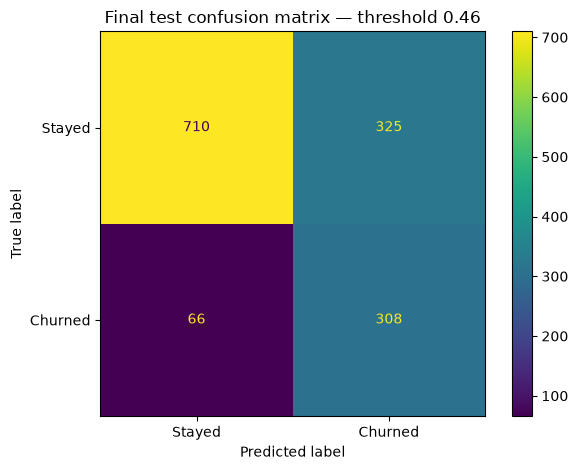

              precision    recall  f1-score   support

      Stayed       0.91      0.69      0.78      1035
     Churned       0.49      0.82      0.61       374

    accuracy                           0.72      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.80      0.72      0.74      1409



In [102]:
# refit using all non-test data. The validation-selected threshold is retained.
final_model = selected_candidate
final_model.fit(X_train_full, y_train_full)

# predict churn probabilities on the test set.
test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= selected_threshold).astype(int) # convert probabilities into class predictions using the selected threshold.

# evaluate the final model on the unseen test set.
final_test_metrics = evaluate_probabilities(y_test, test_probabilities, threshold=selected_threshold)
final_test_metrics_df = pd.DataFrame([final_test_metrics], index=[selected_model_name])
display(final_test_metrics_df.round(3))

# create and visualize the confusion matrix.
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Stayed", "Churned"]).plot(values_format="d")
plt.title(f"Final test confusion matrix — threshold {selected_threshold:.2f}")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test, test_predictions, target_names=["Stayed", "Churned"], zero_division=0))

The confusion matrix shows that the model identified 308 out of 374 customers who churned (Recall = 82.4%), while 710 customers who stayed were correctly classified. However, 325 customers were incorrectly flagged as likely to churn.

## 12. Review the final test errors

 how many churners were detected and how many were missed. False negatives are customers who churned but were not flagged; false positives are customers flagged as likely to churn who actually stayed. These counts help interpret Recall and Precision in practical terms.

In [103]:
# create error summary 
tn, fp, fn, tp = cm.ravel()
error_summary = pd.DataFrame({
    "Measure": ["True negatives", "False positives", "False negatives", "True positives"],
    "Count": [tn, fp, fn, tp]})
display(error_summary)
print(f"Test recall: {recall_score(y_test, test_predictions, zero_division=0):.3f}")
print(f"Test precision: {precision_score(y_test, test_predictions, zero_division=0):.3f}")

,Measure,Count
0,True negatives,710
1,False positives,325
2,False negatives,66
3,True positives,308


Test recall: 0.824
Test precision: 0.487


## 13. Feature importance on an independent holdout

permutation importance will be used on a separate holdout that was not used to train the model, select the candidate, or choose the threshold. This avoids reusing the validation set for feature importance and keeps the test set reserved for the final performance estimate. 

In [104]:
from sklearn.inspection import permutation_importance

# Fit a copy of the selected candidate on training data only.
importance_model = clone(selected_candidate)
importance_model.fit(X_train, y_train)

perm = permutation_importance(
    importance_model, X_importance, y_importance,
    scoring="recall", n_repeats=8,
    random_state=RANDOM_STATE, n_jobs=-1)

importance_df = pd.DataFrame({
    "feature": X_importance.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std,
}).sort_values("importance_mean", ascending=False)

display(importance_df.head(15).round(4))

,feature,importance_mean,importance_std
4,tenure,0.237,0.038
14,Contract,0.126,0.015
7,InternetService,0.027,0.009
18,TotalCharges,0.017,0.014
15,PaperlessBilling,0.013,0.006
8,OnlineSecurity,0.012,0.013
13,StreamingMovies,0.010,0.006
12,StreamingTV,0.010,0.007
16,PaymentMethod,0.009,0.011
3,Dependents,0.007,0.002


The permutation importance analysis shows that tenure is the most influential feature in the model, followed by contract,internetService, and totalCharges. this indicates that customer contract type have an important role in predicting churn. other features have very low or slightly negative importance values, suggesting limited predictive power.

## 14. Save the fitted model 

saveing the complete fitted preprocessing-and-model pipeline, the selected threshold, feature names, and target mapping in one artifact. and  also saveing a JSON metadata file with the final test metrics.

In [110]:
artifact = {
    "model": final_model,
    "threshold": float(selected_threshold),
    "features": list(X_train_full.columns),
    "primary_metric": "F1",
    "target_mapping": {"No": 0, "Yes": 1},
    "model_name": selected_model_name,
    "random_state": RANDOM_STATE}

joblib.dump(artifact, ARTIFACT_PATH)

metadata = {
    "model_name": selected_model_name,
    "threshold": float(selected_threshold),
    "features": list(X_train_full.columns),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "target_mapping": {"No": 0, "Yes": 1},
    "random_state": RANDOM_STATE,
    "project_priority_metric": "Recall",
    "final_selection_metric": "F1",
    "threshold_selection_metric": "F1",
    "test_metrics": {key: float(value) for key, value in final_test_metrics.items()}}

with open(METADATA_PATH, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

print(f"Saved model artifact: {Path(ARTIFACT_PATH).resolve()}")
print(f"Saved model metadata: {Path(METADATA_PATH).resolve()}")
print(f"Model: {selected_model_name} | Threshold: {selected_threshold:.2f}")

Saved model artifact: E:\depi\final project\churn_model.pkl
Saved model metadata: E:\depi\final project\churn_model_metadata.json
Model: Logistic Regression | Threshold: 0.46


## 15. Verify that the saved artifact can be loaded


In [108]:
loaded_artifact = joblib.load(ARTIFACT_PATH)
loaded_model = loaded_artifact["model"]
loaded_threshold = loaded_artifact["threshold"]

loaded_probabilities = loaded_model.predict_proba(X_test)[:, 1]
loaded_predictions = (loaded_probabilities >= loaded_threshold).astype(int)

assert np.allclose(loaded_probabilities, test_probabilities)
assert np.array_equal(loaded_predictions, test_predictions)

print("Artifact load test passed.")
print("Saved model:", loaded_artifact["model_name"])
print("Saved threshold:", loaded_threshold)

Artifact load test passed.
Saved model: Logistic Regression
Saved threshold: 0.46
